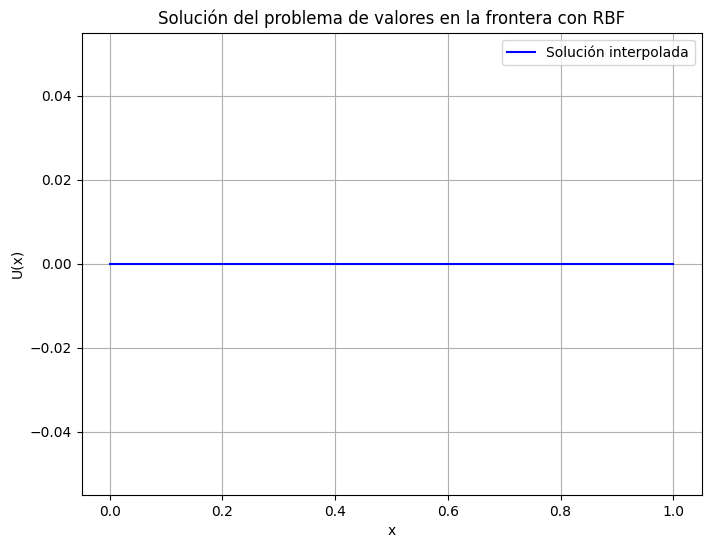

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Definir la función RBF (en este caso, Gaussiana)
def rbf_gaussian(epsilon, r):
    return np.exp(-epsilon * r**2)

# Parámetros
epsilon = 1.0  # Parámetro de la función Gaussiana
xp = 1.0       # Extremo derecho del dominio
n_points = 20  # Número de puntos de colocación

# Puntos de colocación equidistantes en el dominio
x_points = np.linspace(0, xp, n_points)

# Construir la matriz de interpolación
interpolation_matrix = np.zeros((n_points, n_points))

for i in range(n_points):
    for j in range(n_points):
        r = np.abs(x_points[i] - x_points[j])
        interpolation_matrix[i, j] = rbf_gaussian(epsilon, r)

# Resolver el sistema de ecuaciones para encontrar los coeficientes
# En este ejemplo, f(x) se asume como cero.
f_values = np.zeros(n_points)  # f(x) = 0 para este caso
coefficients = np.linalg.solve(interpolation_matrix, f_values)

# Función para calcular la solución en un punto dado x
def interpolate_solution(x):
    result = 0.0
    for i in range(n_points):
        r = np.abs(x - x_points[i])
        result += coefficients[i] * rbf_gaussian(epsilon, r)
    return result

# Calcular la solución en una serie de puntos para graficar
x_plot = np.linspace(0, xp, 100)
u_plot = [interpolate_solution(x) for x in x_plot]

# Graficar la solución
plt.figure(figsize=(8, 6))
plt.plot(x_plot, u_plot, label='Solución interpolada', color='b')
plt.xlabel('x')
plt.ylabel('U(x)')
plt.title('Solución del problema de valores en la frontera con RBF')
plt.grid(True)
plt.legend()
plt.show()

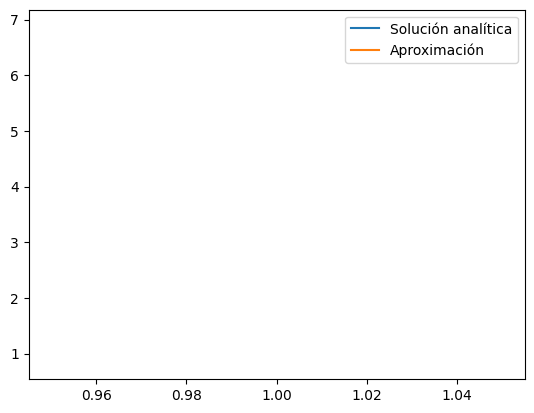

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.sin(x)

def phi(x, n, c):
    return (x**2 + c)**n

def solve(n, c, x_p, x_min, x_max, x):
    # Puntos de colocación
    x_i = np.linspace(x_min, x_max, 5)

    # Coeficientes de la aproximación
    alpha_i = np.ones(5)

    # Aproximación de la solución
    U = np.sum(alpha_i * phi(x_i - x, n, c), axis=0)

    return U

# Parámetros del problema
x = 1
n = 1
c = 1
x_p = 1
x_min = 0
x_max = x_p

# Aproximación de la solución
U = solve(n, c, x_p, x_min, x_max, x)

# Solución analítica
u = lambda x: np.sin(x)

# Gráfica
plt.plot(x, u(x), label="Solución analítica")
plt.plot(x, U, label="Aproximación")
plt.legend()
plt.show()

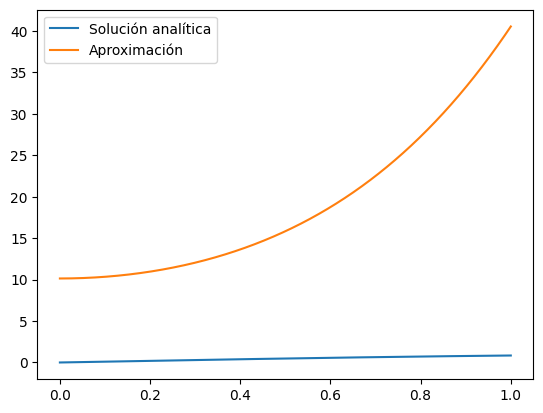

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return np.sin(x)

def phi(x, n, c):
    return (x**2 + c)**n

def solve(n, c, x_p, x_min, x_max):
    # Puntos de colocación
    x_i = np.linspace(x_min, x_max, 5)

    # Crear una malla de puntos x
    x = np.linspace(x_min, x_max, 1000)

    # Coeficientes de la aproximación
    alpha_i = np.ones(5)

    # Aproximación de la solución
    U = np.zeros_like(x)

    for i in range(5):
        U += alpha_i[i] * phi(x, n, c) * phi(x_i[i], n, c)

    return U

# Parámetros del problema
n = 2
c = 1
x_p = 1
x_min = 0
x_max = x_p

# Aproximación de la solución
U = solve(n, c, x_p, x_min, x_max)

# Solución analítica
u = lambda x: np.sin(x)

# Gráfica
plt.plot(np.linspace(x_min, x_max, 1000), u(np.linspace(x_min, x_max, 1000)), label="Solución analítica")
plt.plot(np.linspace(x_min, x_max, 1000), U, label="Aproximación")
plt.legend()
plt.show()
